# Modelo escolhido — Random Forest com SMOTE

**Threshold: 0,70. Métrica principal: F1. Classe positiva: fraude (Class=1).**

O resultado escolhido foi **Precision de 89,19%, Recall de 75,00% e F1 de 81,48%**,
na **última validação temporal dentro do TRAIN (fold 3)**. Esses valores não são
médias de CV nem métricas do TEST. Neste notebook aparece somente o Random Forest
com SMOTE, com os mesmos estilos de gráficos dos demais notebooks e valores nas barras.

O código reutilizável está em `src/fraud_detection/model_select.py`. O notebook apenas
lê tabelas e figuras persistidas: abri-lo não treina modelos. Para reproduzir os
relatórios: `python -m fraud_detection.model_select`. A execução reconstrói apenas
os três folds do RF escolhido, confirma as métricas originais e aplica 0,70.
Nenhum novo TEST é pontuado nem artefato histórico de inferência é substituído.

**Atenção à seleção:** modelo e threshold foram escolhidos após inspecionar resultados
do TRAIN. As métricas são exploratórias e condicionadas à escolha, sem validação
externa ao ajuste do limiar. O TEST histórico também já foi consultado em rodadas
anteriores. Uma confirmação independente exige dados novos.

In [1]:
# Localiza a raiz e carrega somente artefatos agregados, sem fit ou predição.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra o notebook pela raiz ou pela pasta notebooks.")
METRICS = ROOT / "reports/metrics"
FIGURES = ROOT / "reports/figures"

def read_json(path):
    if not path.exists():
        raise FileNotFoundError("Execute python -m fraud_detection.model_select antes de abrir.")
    return json.loads(path.read_text(encoding="utf-8"))

def table(name):
    return pd.read_csv(METRICS / f"model_select_{name}.csv")

def figure(name, width=1100):
    display(Image(filename=str(FIGURES / f"model_select_{name}.png"), width=width))

def show(frame):
    display(readable_table(frame))

result = read_json(METRICS / "model_select_metrics.json")
manifest = read_json(ROOT / "reports/experiments/model_select_manifest.json")
assert result["model"] == "random_forest__smote" and result["threshold"] == 0.7
assert not manifest["test_evaluated"] and manifest["original_metrics_reproduced"]

## 1. Receita, dados e rastreabilidade

Cada linha é uma transação; as features são numéricas. O pipeline é
imputação pela mediana → StandardScaler → SMOTE → Random Forest. As transformações
aprendem apenas no treino do fold; SMOTE não atua na validação ou na inferência.
São usados pesos uniformes (`class_weight=None`) e seed 42.

SMOTE cria fraudes sintéticas até a razão fraude/legítima 0,1: aproximadamente
9,09% das linhas após reamostragem. Preserva todas as legítimas; não há undersampling.
O nome `smotec` nos outros notebooks refere-se a SMOTE numérico, não a SMOTENC.

As features são selecionadas dentro do treino de cada fold pela regra conjunta:
remover somente quando `|Pearson| < 0,090 E importância por permutação < 0,100`.
Aqui reutilizamos a seleção salva, sem escolher novas features. O fold 3 treina
com 156.133 transações e avalia as 54.159 seguintes, das quais 44 são fraudes.
A origem e o hash do CSV precisam coincidir com o experimento original.

In [2]:
# Expõe somente a configuração do Random Forest escolhido.
display({
    "Modelo": result["model"],
    "Origem das métricas principais": result["source"],
    "Threshold": result["threshold"],
    "Métrica principal": result["primary_metric"],
    "Treino do fold 3": manifest["fit_rows"],
    "Validação do fold 3": manifest["validation_rows"],
    "Fraudes na validação do fold 3": manifest["validation_frauds"],
    "Time inicial da validação": manifest["validation_time_min"],
    "Time final da validação": manifest["validation_time_max"],
    "Features mantidas": result["selected_features"],
    "Hiperparâmetros RF": manifest["model_parameters"],
    "Dataset SHA-256": manifest["dataset_sha256"],
    "Métricas originais reproduzidas": manifest["original_metrics_reproduced"],
    "TEST avaliado nesta execução": manifest["test_evaluated"],
})
show(table("sampling_counts"))

{'Modelo': 'random_forest__smote',
 'Origem das métricas principais': 'Última validação temporal do TRAIN (fold 3), não TEST nem média CV',
 'Threshold': 0.7,
 'Métrica principal': 'f1',
 'Treino do fold 3': 156133,
 'Validação do fold 3': 54159,
 'Fraudes na validação do fold 3': 44,
 'Time inicial da validação': 108799.0,
 'Time final da validação': 138230.0,
 'Features mantidas': ['V1',
  'V2',
  'V3',
  'V4',
  'V5',
  'V7',
  'V9',
  'V10',
  'V11',
  'V12',
  'V14',
  'V16',
  'V17',
  'V18'],
 'Hiperparâmetros RF': {'bootstrap': True,
  'ccp_alpha': 0.0,
  'class_weight': None,
  'criterion': 'gini',
  'max_depth': 14,
  'max_features': 'sqrt',
  'max_leaf_nodes': None,
  'max_samples': None,
  'min_impurity_decrease': 0.0,
  'min_samples_leaf': 2,
  'min_samples_split': 2,
  'min_weight_fraction_leaf': 0.0,
  'monotonic_cst': None,
  'n_estimators': 160,
  'n_jobs': 2,
  'oob_score': False,
  'random_state': 42,
  'verbose': 0,
  'warm_start': False},
 'Dataset SHA-256': '76274

,Estratégia de balanceamento,Receita,Fold temporal,Legítimas antes do sampler,Fraudes antes do sampler,Legítimas após sampler,Fraudes após sampler,Legítimas removidas,Fraudes sintéticas criadas,Razão fraudes/legítimas após sampler
0,smote,random_forest__smote,1,45.697,143,45.697,4.569,0,4.426,"0,1000"
1,smote,random_forest__smote,2,104.202,227,104.202,10.420,0,10.193,"0,1000"
2,smote,random_forest__smote,3,155.801,332,155.801,15.580,0,15.248,"0,1000"


## 2. F1, Recall e Precision — modelo escolhido, threshold 0,70

As três barras descrevem **o mesmo modelo na mesma validação (fold 3)**.
Os rótulos mostram os valores em porcentagem.

- **Recall:** TP/(TP+FN), a fração das fraudes reais que recebeu alerta.
- **Precision:** TP/(TP+FP), a fração dos alertas que era fraude real.
- **F1:** 2PR/(P+R), a média harmônica de Precision e Recall, com pesos iguais.

Precision de 89,19% significa que 33 dos 37 alertas eram fraudes. Recall de 75%
significa que 33 das 44 fraudes foram detectadas; 11 ficaram sem alerta.
A apresentação isolada não demonstra superioridade fora desta validação.

,Limiar de alerta,F1 (%),Recall (%),Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas
0,"0,7000",81.48%,75.00%,89.19%,"0,7130",33,4,11,54.111


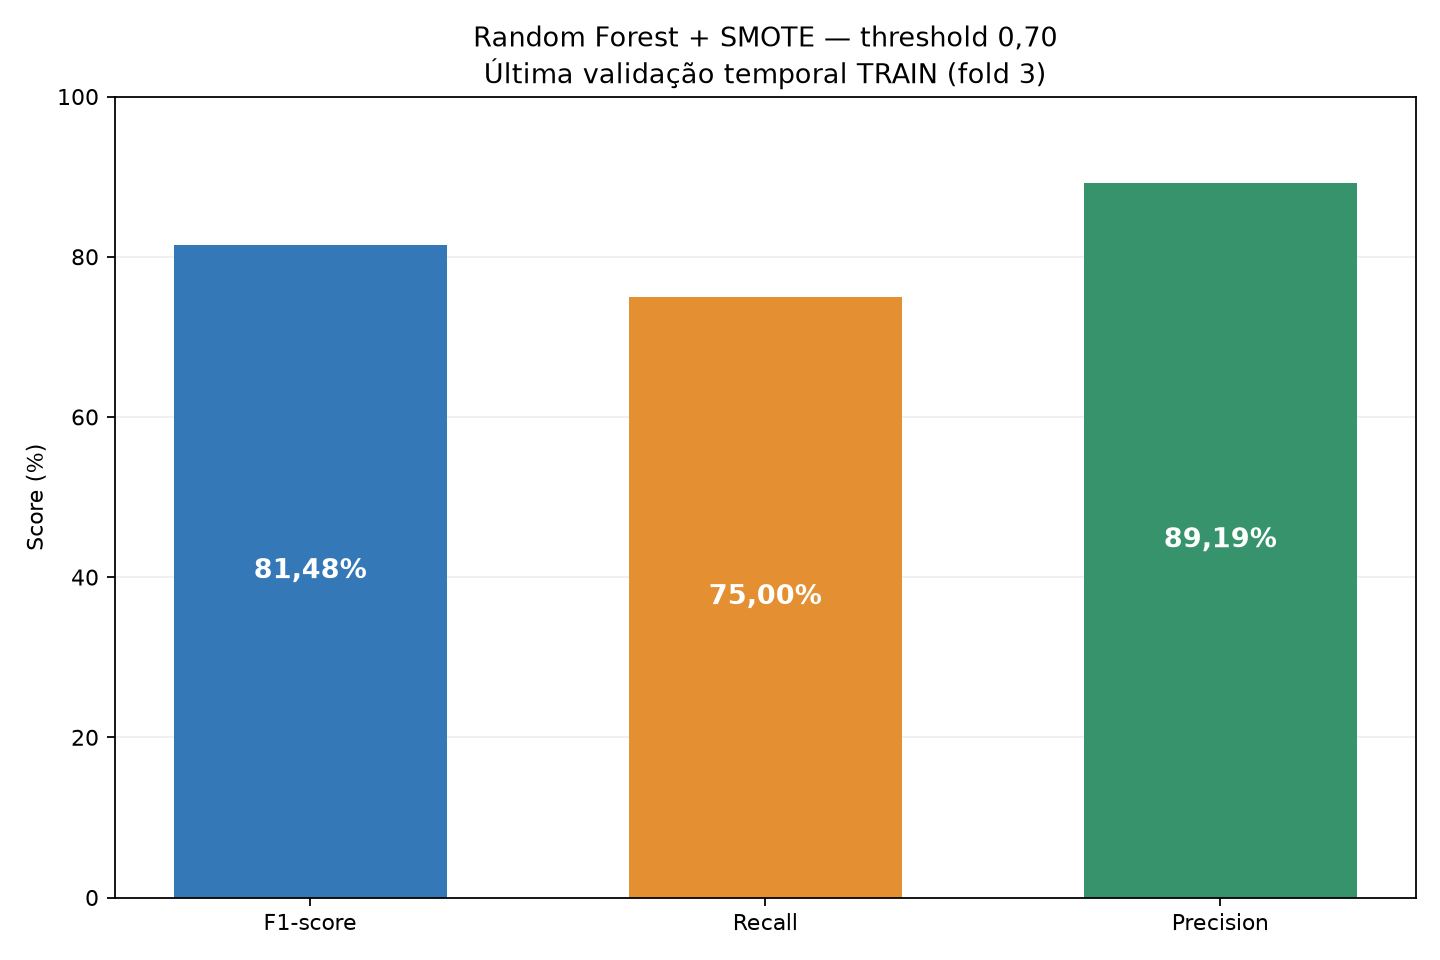

In [3]:
show(pd.DataFrame([{key: result[key] for key in
    ["threshold", "f1", "recall", "precision", "average_precision", "tp", "fp", "fn", "tn"]
}]))
figure("f1_recall_precision", 950)

## 3. Matriz de confusão — contagens e proporções por classe real

**TN:** legítima corretamente liberada. **FP:** legítima que gerou alerta.
**FN:** fraude sem alerta. **TP:** fraude detectada.

Na matriz normalizada, cada linha soma 100%. A linha de fraude mostra Recall e
taxa de fraudes perdidas; a linha de legítima mostra especificidade e FPR.
O número de legítimas é muito maior, então contagens e taxas devem ser lidas juntas.

,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas
0,54.111,4,11,33


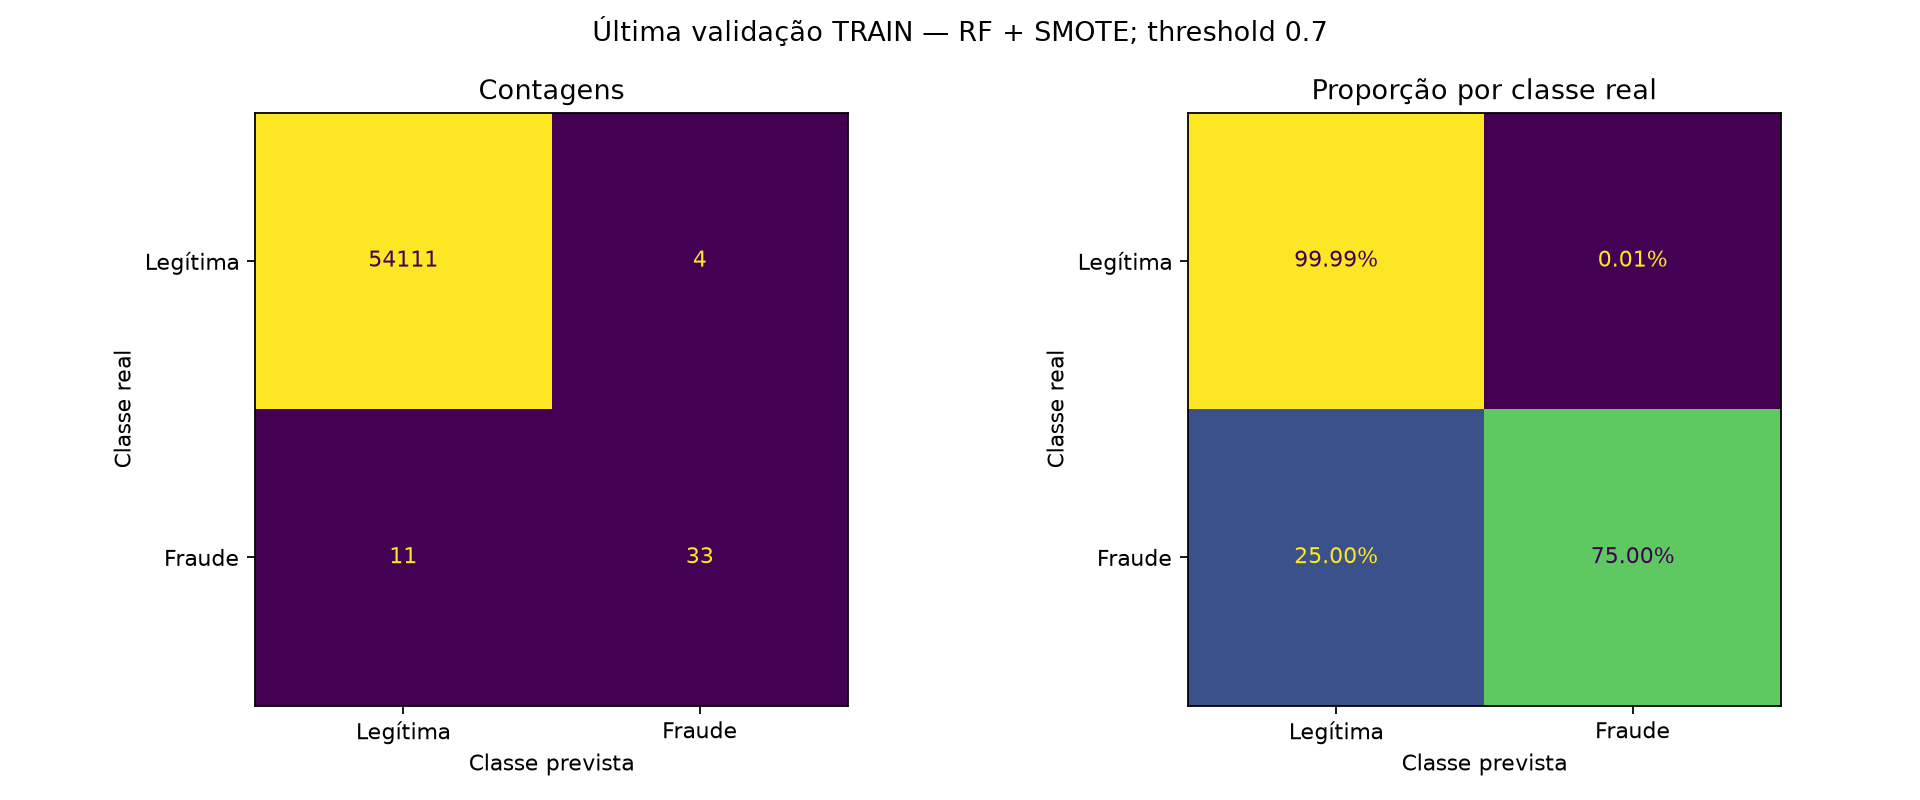

In [4]:
show(pd.DataFrame([{key: result[key] for key in ["tn", "fp", "fn", "tp"]}]))
figure("confusion")

## 4. Todas as métricas e seus denominadores

A tabela traz fórmulas, unidades e direção desejável. Acurácia pode parecer muito
alta por causa da predominância de transações legítimas. Balanced Accuracy dá
peso igual ao Recall e à especificidade.

**FPR** divide FP pelas legítimas reais; **FDR** divide FP pelos alertas.
**FNR** divide FN pelas fraudes reais; a parcela de liberadas que era fraude divide
FN pelo total liberado. São perguntas diferentes. Denominador zero significa
métrica não definida, não evidência de desempenho nulo.

Métricas com unidade `%` já estão na escala 0–100 na tabela abaixo.

In [5]:
definitions = table("metric_definitions")
percentages = definitions.loc[definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor (%)", "definition": "Significado e denominador",
    "preferred": "Direção desejável",
})
display(percentages[["Métrica", "Valor (%)", "Significado e denominador", "Direção desejável"]]
        .style.format({"Valor (%)": "{:.4f}%"}))
probabilistic = definitions.loc[~definitions.unit.eq("%")].rename(columns={
    "name": "Métrica", "value": "Valor", "unit": "Unidade", "definition": "Significado",
    "preferred": "Direção desejável",
})
display(probabilistic[["Métrica", "Valor", "Unidade", "Significado", "Direção desejável"]]
        .style.format({"Valor": "{:.6f}"}))

,Métrica,Valor (%),Significado e denominador,Direção desejável
0,Precision,89.1892%,TP/(TP+FP): fração dos alertas que era fraude,Maior
1,Recall / sensibilidade,75.0000%,TP/(TP+FN): fração das fraudes detectada,Maior
2,F1,81.4815%,2PR/(P+R): média harmônica simétrica de Precision e Recall,Maior
3,Especificidade,99.9926%,TN/(TN+FP): legítimas corretamente liberadas,Maior
4,Acurácia,99.9723%,(TP+TN)/n: acertos totais; pode enganar em classe rara,Maior
5,Balanced Accuracy,87.4963%,(Recall+Especificidade)/2,Maior
6,Valor preditivo negativo,99.9797%,TN/(TN+FN): legítimas entre não alertadas,Maior
7,Taxa de falsos positivos (FPR),0.0074%,FP/(FP+TN): legítimas alertadas,Menor
8,Taxa de falsos negativos (FNR),25.0000%,FN/(FN+TP): fraudes não detectadas,Menor
9,Parcela de alertas falsos (FDR),10.8108%,FP/(FP+TP): alertas que eram legítimos,Menor


,Métrica,Valor,Unidade,Significado,Direção desejável
13,Average Precision (AP),0.712960,score 0–1,Resumo de Precision ponderado pelos ganhos de Recall; usa scores,Maior
14,Área trapezoidal PR,0.711410,score 0–1,Integral trapezoidal da curva Precision–Recall; difere de AP,Maior
15,ROC-AUC,0.977532,score 0–1,Ordenação fraude vs. legítima; complemento à AP,Maior
16,Log Loss,0.010933,perda,Perda probabilística; penaliza erros confiantes,Menor
17,Brier score,0.000853,erro quadrático,Média de (probabilidade−rótulo)²,Menor
18,Coeficiente de Matthews (MCC),0.817741,score −1–1,Associação entre decisões e rótulos usando TN/FP/FN/TP,Maior
19,Kappa de Cohen,0.814677,score −1–1,Concordância corrigida pela concordância esperada ao acaso,Maior


## 5. Curvas Precision–Recall / AUPRC e ROC

**Average Precision (AP)** resume a curva PR ponderando a precisão pelos ganhos
de Recall; usa scores contínuos. A área trapezoidal da PR é calculada por outro
método e pode diferir da AP. A linha de prevalência é a referência ingênua.
O ponto vermelho marca o threshold escolhido, 0,70.

**ROC-AUC** avalia a ordenação entre fraude e legítima. Complementa a PR, mas
não substitui Recall, Precision, AP e contagens para uma classe rara.
AP e ROC-AUC não mudam quando somente o threshold muda sobre os mesmos scores.

,AP (score),pr_auc_trapezoid,ROC-AUC (score),prevalence
0,"0,7130","0,7114","0,9775","0,0008"


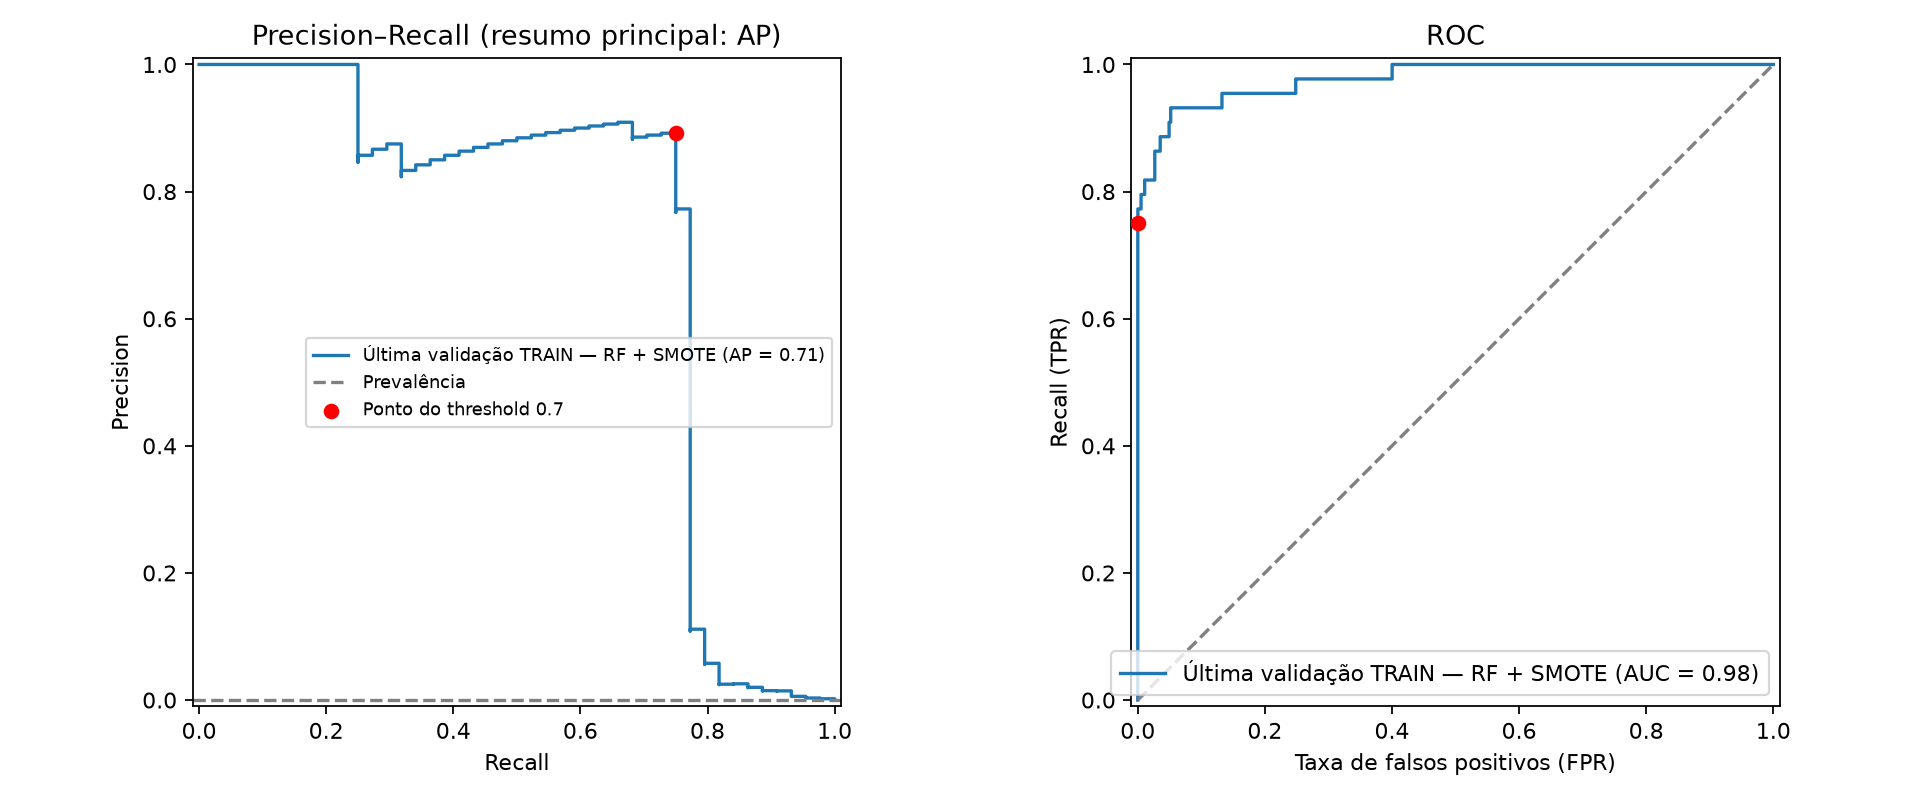

In [6]:
show(pd.DataFrame([{key: result[key] for key in
    ["average_precision", "pr_auc_trapezoid", "roc_auc", "prevalence"]
}]))
figure("pr_roc")

## 6. Relatório por classe e médias

Na linha **Fraude (1)** estão as métricas principais. Na linha **Legítima (0)**,
a classe 0 é tratada como positiva para esse cálculo: seu Recall equivale à
especificidade, e sua Precision ao valor preditivo negativo.

**Suporte** é o número de transações reais. A média **macro** dá o mesmo peso às
classes; a média **ponderada** usa seus tamanhos e é dominada pelas legítimas.
Uma média ponderada alta não significa que todas as fraudes foram detectadas.

In [7]:
classification = read_json(METRICS / "model_select_classification_report.json")
per_class = pd.DataFrame({key: value for key, value in classification.items()
                          if isinstance(value, dict)}).T
per_class = per_class.rename(columns={"f1-score": "f1", "support": "Suporte"},
    index={"macro avg": "Média macro", "weighted avg": "Média ponderada"})
per_class["Suporte"] = per_class["Suporte"].astype(int)
show(per_class)

,Precision (%),Recall (%),F1 (%),Suporte
Legítima (0),99.98%,99.99%,99.99%,54.115
Fraude (1),89.19%,75.00%,81.48%,44
Média macro,94.58%,87.50%,90.73%,54.159
Média ponderada,99.97%,99.97%,99.97%,54.159


## 7. Treino versus validação e dispersão entre folds

Somente Random Forest com SMOTE, agora com **threshold fixo 0,70 em todos os folds**.
Os gráficos mostram F1, Recall e Precision de treino e de validação, sem candidatos
adicionais. Scores de treino usam a distribuição original, sem incluir sintéticos
na avaliação. Os períodos e o tamanho do treino mudam juntos: não é uma learning
curve controlada.

Uma diferença grande entre treino e validação pode sugerir sobreajuste ou mudança
temporal. Média e desvio entre folds descrevem estabilidade; o desvio não é um
intervalo de confiança. Os folds foram inspecionados antes de escolher o limiar,
então estes scores não são uma validação externa dessa escolha.

,Fold temporal,Features utilizadas,Limiar de alerta,train_f1,F1 (%),train_recall,Recall (%),train_precision,Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas
0,1,16,"0,7000",99.65%,74.07%,99.30%,59.52%,100.00%,98.04%,"0,7752",50,1,34,58.504
1,2,15,"0,7000",97.30%,80.21%,95.15%,73.33%,99.54%,88.51%,"0,7788",77,10,28,51.589
2,3,14,"0,7000",95.41%,81.48%,93.98%,75.00%,96.89%,89.19%,"0,7130",33,4,11,54.111


,Métrica,Média dos folds (%),Desvio entre folds (p.p.)
0,F1,78.59,3.96
1,Recall,69.29,8.50
2,Precision,91.91,5.32
3,AP,75.57,3.70


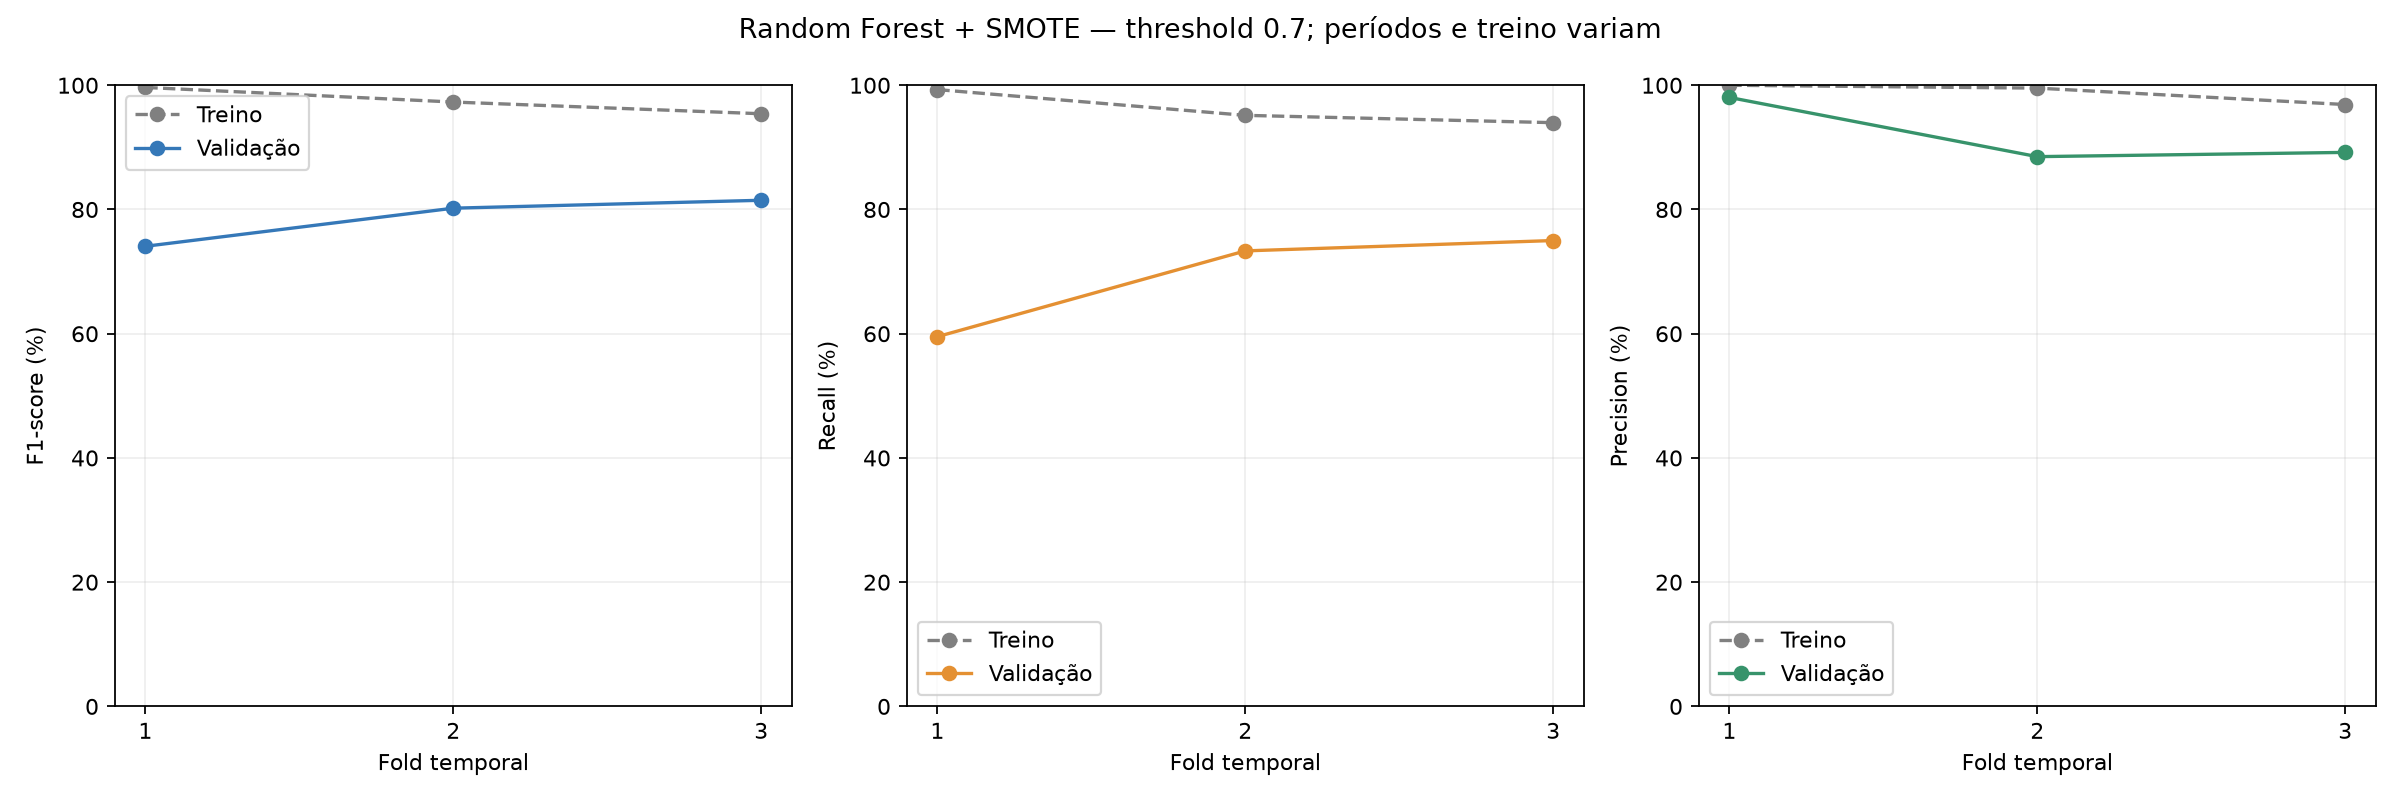

In [8]:
folds = table("folds")
show(folds[["fold", "n_features", "threshold", "train_f1", "f1", "train_recall", "recall",
            "train_precision", "precision", "average_precision", "tp", "fp", "fn", "tn"]])
summary = pd.DataFrame({
    "Métrica": ["F1", "Recall", "Precision", "AP"],
    "Média dos folds (%)": [100 * folds[key].mean() for key in ["f1", "recall", "precision", "average_precision"]],
    "Desvio entre folds (p.p.)": [100 * folds[key].std(ddof=1) for key in ["f1", "recall", "precision", "average_precision"]],
})
display(summary.style.format({"Média dos folds (%)": "{:.2f}", "Desvio entre folds (p.p.)": "{:.2f}"}))
figure("train_validation", 1300)

## 8. OOF temporal agregado — separado do resultado principal

OOF reúne previsões das três janelas de validação, sempre posteriores ao treino
do respectivo fold. O prefixo inicial do TRAIN só treina e não tem previsão OOF.
O mesmo threshold 0,70 é usado nos três folds.

A métrica calculada ao juntar todas essas previsões **não é a média dos folds** e
não precisa coincidir com os 89,19% de Precision e 75% de Recall do último fold.
Cada gráfico desta seção está identificado como OOF, sem resultados de TEST.

Cobertura OOF: **164,452 transações**.

,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,alerts,Taxa de alertas (%),accuracy,negative_predictive_value,false_positive_rate,false_negative_rate,false_discovery_rate,false_omission_rate,prevalence,mcc,cohen_kappa,pr_auc_trapezoid,rows,positives,negatives
0,"0,7579",78.43%,68.67%,91.43%,"0,9366",84.33%,99.99%,"0,0090","0,0007",164.204,15,73,160,"0,7000",175,0.11%,"0,9995","0,9996","0,0001","0,3133","0,0857","0,0004","0,0014","0,7921","0,7841","0,7576",164.452,233,164.219


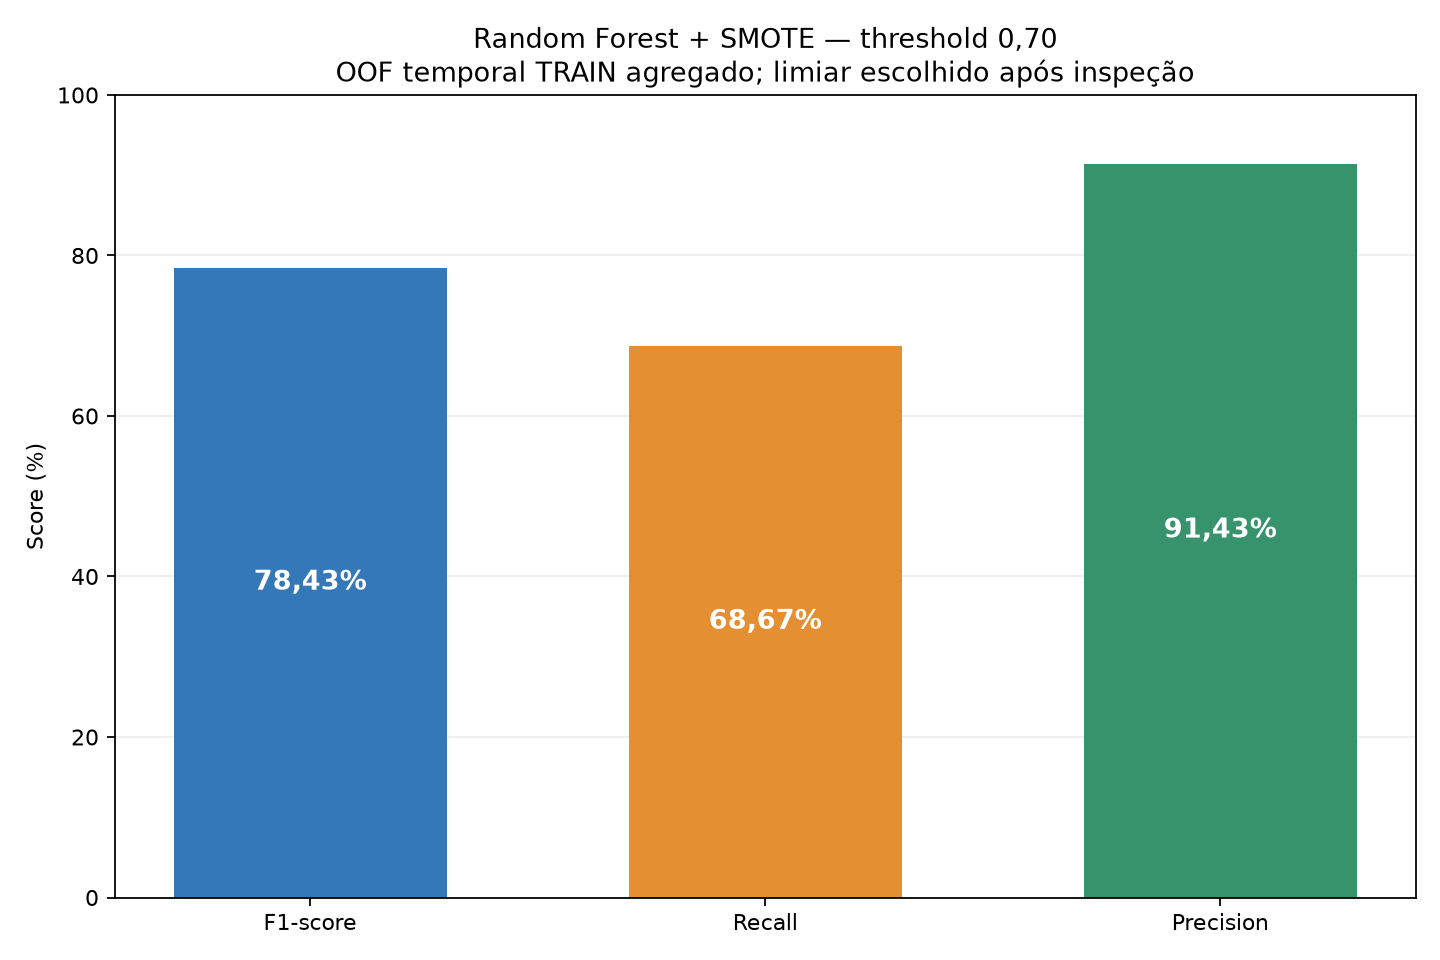

In [9]:
display(Markdown(f"Cobertura OOF: **{manifest['oof_rows']:,} transações**."))
show(table("oof"))
figure("oof_f1_recall_precision", 950)

## 9. Calibração e distribuição dos scores

**Log Loss** penaliza previsões probabilísticas incorretas, sobretudo confiantes;
**Brier** é a média do erro quadrático entre score e rótulo. Menor é melhor.
MCC e Kappa medem concordância entre decisões e rótulos; não são porcentagens.

O painel de confiabilidade compara score médio com frequência real de fraude
por faixa. A diagonal é a referência ideal. A tabela mostra contagens e extremos
de cada faixa. As distribuições à direita são normalizadas dentro de cada classe.

SMOTE modifica a prevalência no treino; não houve calibração. Um score de 0,70
não foi demonstrado como 70% de chance operacional de fraude. As faixas não são
usadas aqui para ajustar probabilidades ou threshold.

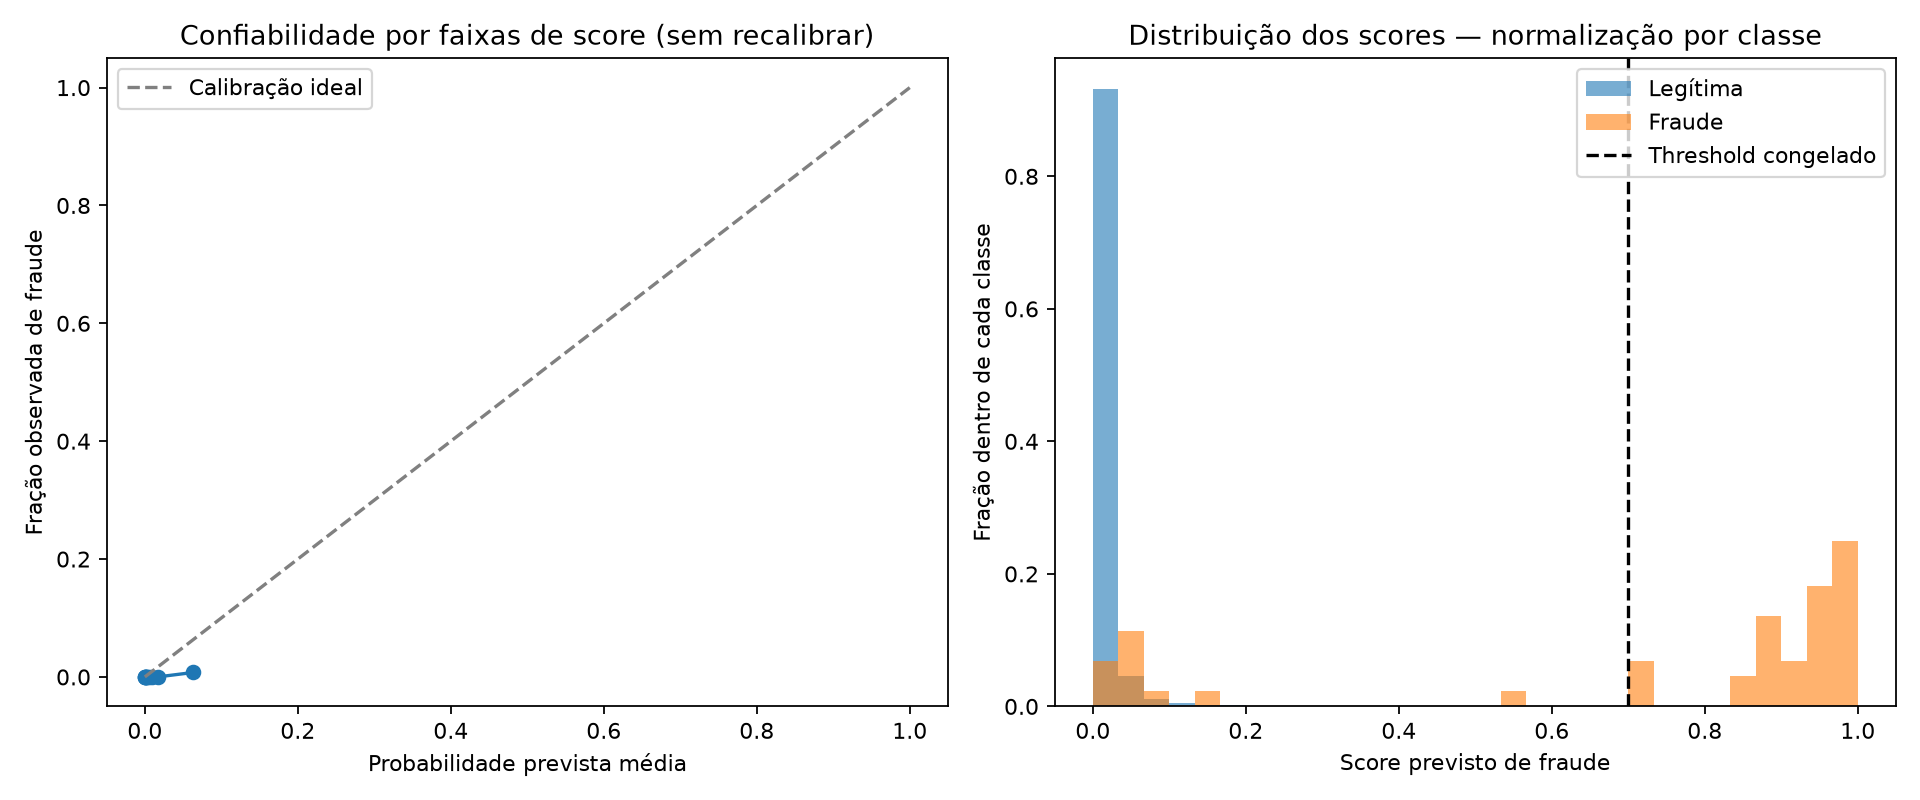

,Faixa de score,Transações,Fraudes,Score médio,Frequência de fraude,Score mínimo,Score máximo
0,"(-0.0009857, 0.000265]",5416,0,0.0170%,0.0000%,0.0000,0.0003
1,"(0.000265, 0.000483]",5416,0,0.0365%,0.0000%,0.0003,0.0005
2,"(0.000483, 0.000815]",5416,0,0.0633%,0.0000%,0.0005,0.0008
3,"(0.000815, 0.00139]",5416,0,0.1073%,0.0000%,0.0008,0.0014
4,"(0.00139, 0.00234]",5416,0,0.1827%,0.0000%,0.0014,0.0023
5,"(0.00234, 0.0042]",5415,1,0.3212%,0.0185%,0.0023,0.0042
6,"(0.0042, 0.00706]",5416,0,0.5499%,0.0000%,0.0042,0.0071
7,"(0.00706, 0.0126]",5416,1,0.9403%,0.0185%,0.0071,0.0126
8,"(0.0126, 0.0249]",5416,1,1.7802%,0.0185%,0.0126,0.0249
9,"(0.0249, 0.999]",5416,41,6.3268%,0.7570%,0.0249,0.9992


In [10]:
figure("calibration_scores")
calibration = table("calibration").rename(columns={
    "score_bin": "Faixa de score", "count": "Transações", "fraud_count": "Fraudes",
    "predicted_probability": "Score médio", "observed_fraud_rate": "Frequência de fraude",
    "min_probability": "Score mínimo", "max_probability": "Score máximo",
})
display(calibration.style.format({"Score médio": "{:.4%}", "Frequência de fraude": "{:.4%}",
                                  "Score mínimo": "{:.4f}", "Score máximo": "{:.4f}"}))

## 10. Correlação com a target versus importância das features

Os painéis mantêm o estilo dos outros notebooks e mostram apenas o RF escolhido.
Pearson/Spearman são associações com Class calculadas no TRAIN; a importância por
permutação mede queda de AP na última validação com o RF que não treinou nela.
O diagnóstico persistido é reutilizado: AP e sua permutação não dependem do threshold.

As escalas são distintas. Importância não é porcentagem nem evidência de causalidade.
A importância interna das árvores também é reportada e pode favorecer certos atributos
ou dividir crédito entre features correlacionadas. Features excluídas têm importância
zero no pipeline porque não foram utilizadas. Nenhuma nova feature é retirada aqui.

,Feature,Usada no último fold?,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
0,Time,False,"-0,0140","-0,0135","0,0000","0,0000","0,0000"
1,V1,True,"-0,1153","-0,0448","0,0078","0,0308","0,0102"
2,V2,True,"0,1017","0,0544","0,0191","0,0036","0,0110"
3,V3,True,"-0,2197","-0,0610","0,0235","0,0128","0,0424"
4,V4,True,"0,1389","0,0640","0,0265","0,0250","0,0450"
5,V5,True,"-0,1154","-0,0366","0,0185","0,0146","0,0081"
6,V6,False,"-0,0475","-0,0401","0,0000","0,0000","0,0000"
7,V7,True,"-0,2106","-0,0497","0,0143","0,0107","0,0214"
8,V8,False,"0,0406","0,0240","0,0000","0,0000","0,0000"
9,V9,True,"-0,1007","-0,0493","0,0104","0,0016","0,0120"


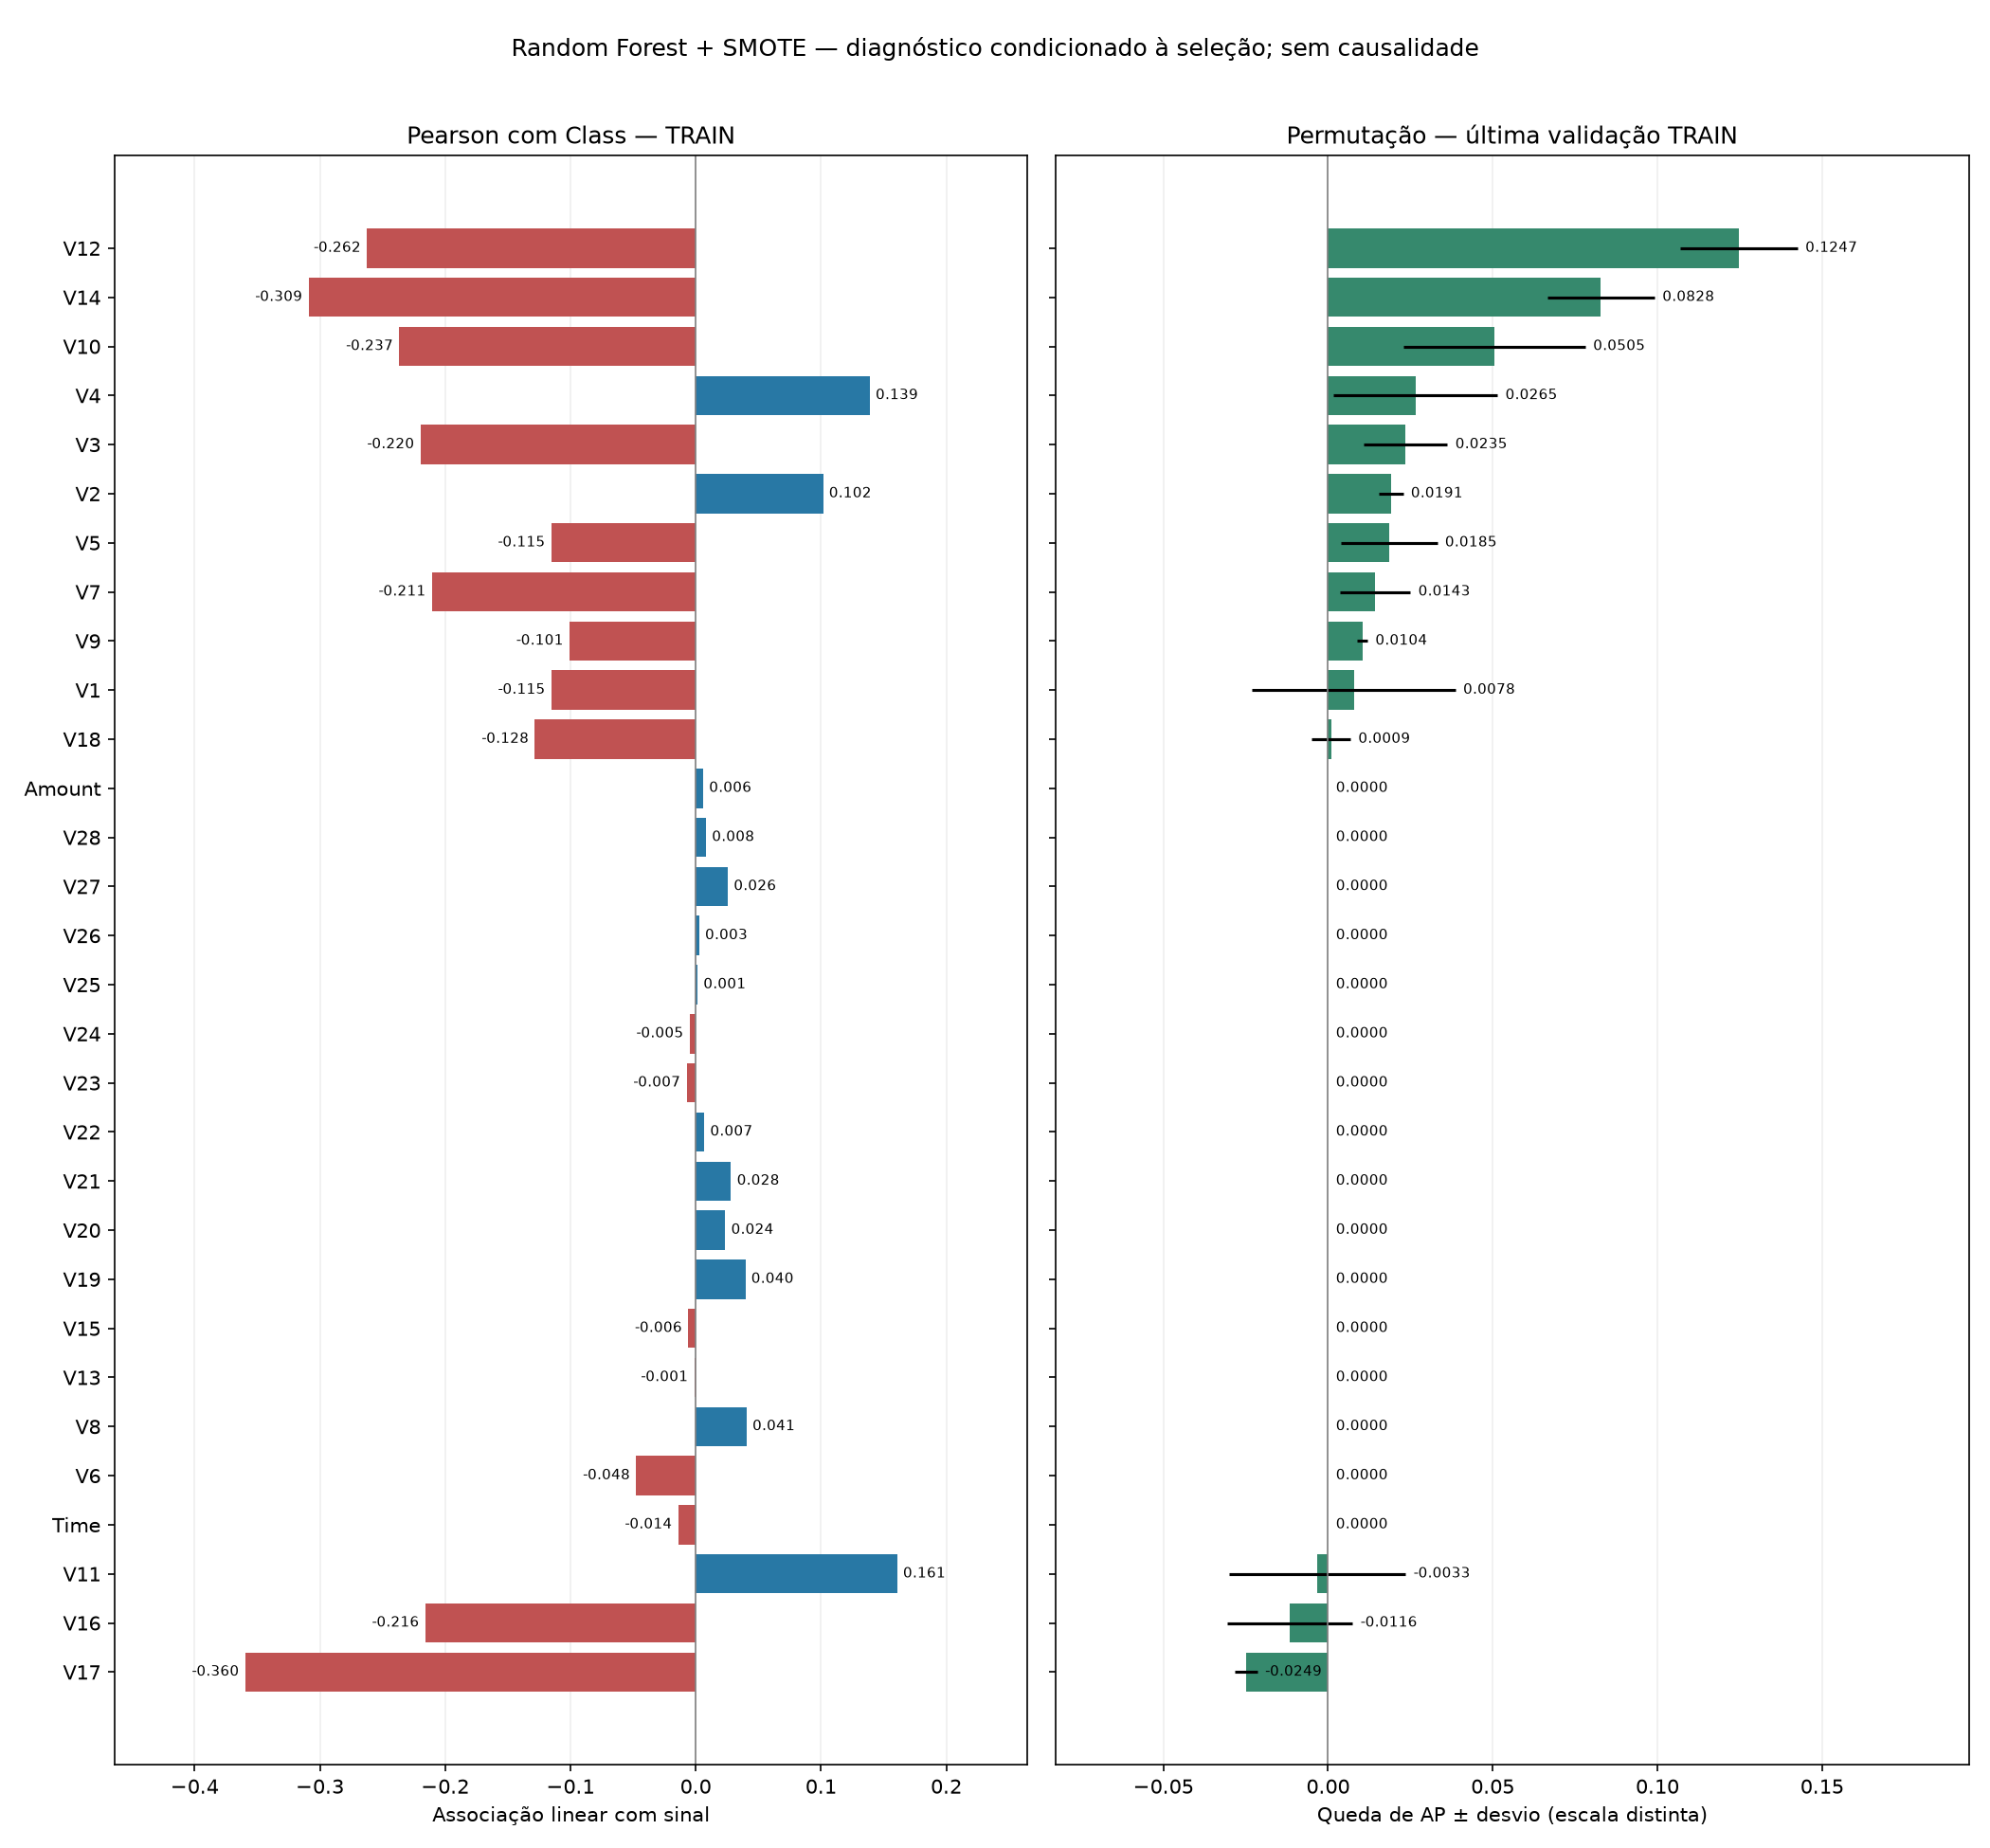

In [11]:
association = table("association_importance")
show(association[["feature", "selected_last_fold", "pearson", "spearman",
                  "permutation_ap", "permutation_std", "tree_importance"]])
figure("association_importance", 1100)

## 11. Sensibilidade por threshold — somente Random Forest

Barras agrupadas de F1, Recall e Precision para o mesmo modelo e a mesma última
validação do TRAIN. A faixa cinza destaca 0,70, escolhido após inspecionar esse
diagnóstico. Não há alegação de threshold ótimo ou validação independente da escolha.

Diminuir o threshold pode ampliar Recall, ao custo de falsos positivos; aumentá-lo
mantém ou reduz Recall. Precision não é garantidamente monotônica nos scores empíricos.
Este notebook não busca outro limiar nem usa TEST para reajustá-lo.

,Limiar de alerta,F1 (%),Recall (%),Precision (%),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,alerts
0,"0,0100",0.66%,95.45%,0.33%,42,12.736,2,41.379,12.778
1,"0,0500",3.79%,88.64%,1.94%,39,1.974,5,52.141,2.013
2,"0,1000",10.57%,79.55%,5.66%,35,583,9,53.532,618
3,"0,2000",36.96%,77.27%,24.29%,34,106,10,54.009,140
4,"0,3000",58.12%,77.27%,46.58%,34,39,10,54.076,73
5,"0,4000",68.69%,77.27%,61.82%,34,21,10,54.094,55
6,"0,5000",74.73%,77.27%,72.34%,34,13,10,54.102,47
7,"0,6000",77.65%,75.00%,80.49%,33,8,11,54.107,41
8,"0,7000",81.48%,75.00%,89.19%,33,4,11,54.111,37
9,"0,8000",76.92%,68.18%,88.24%,30,4,14,54.111,34


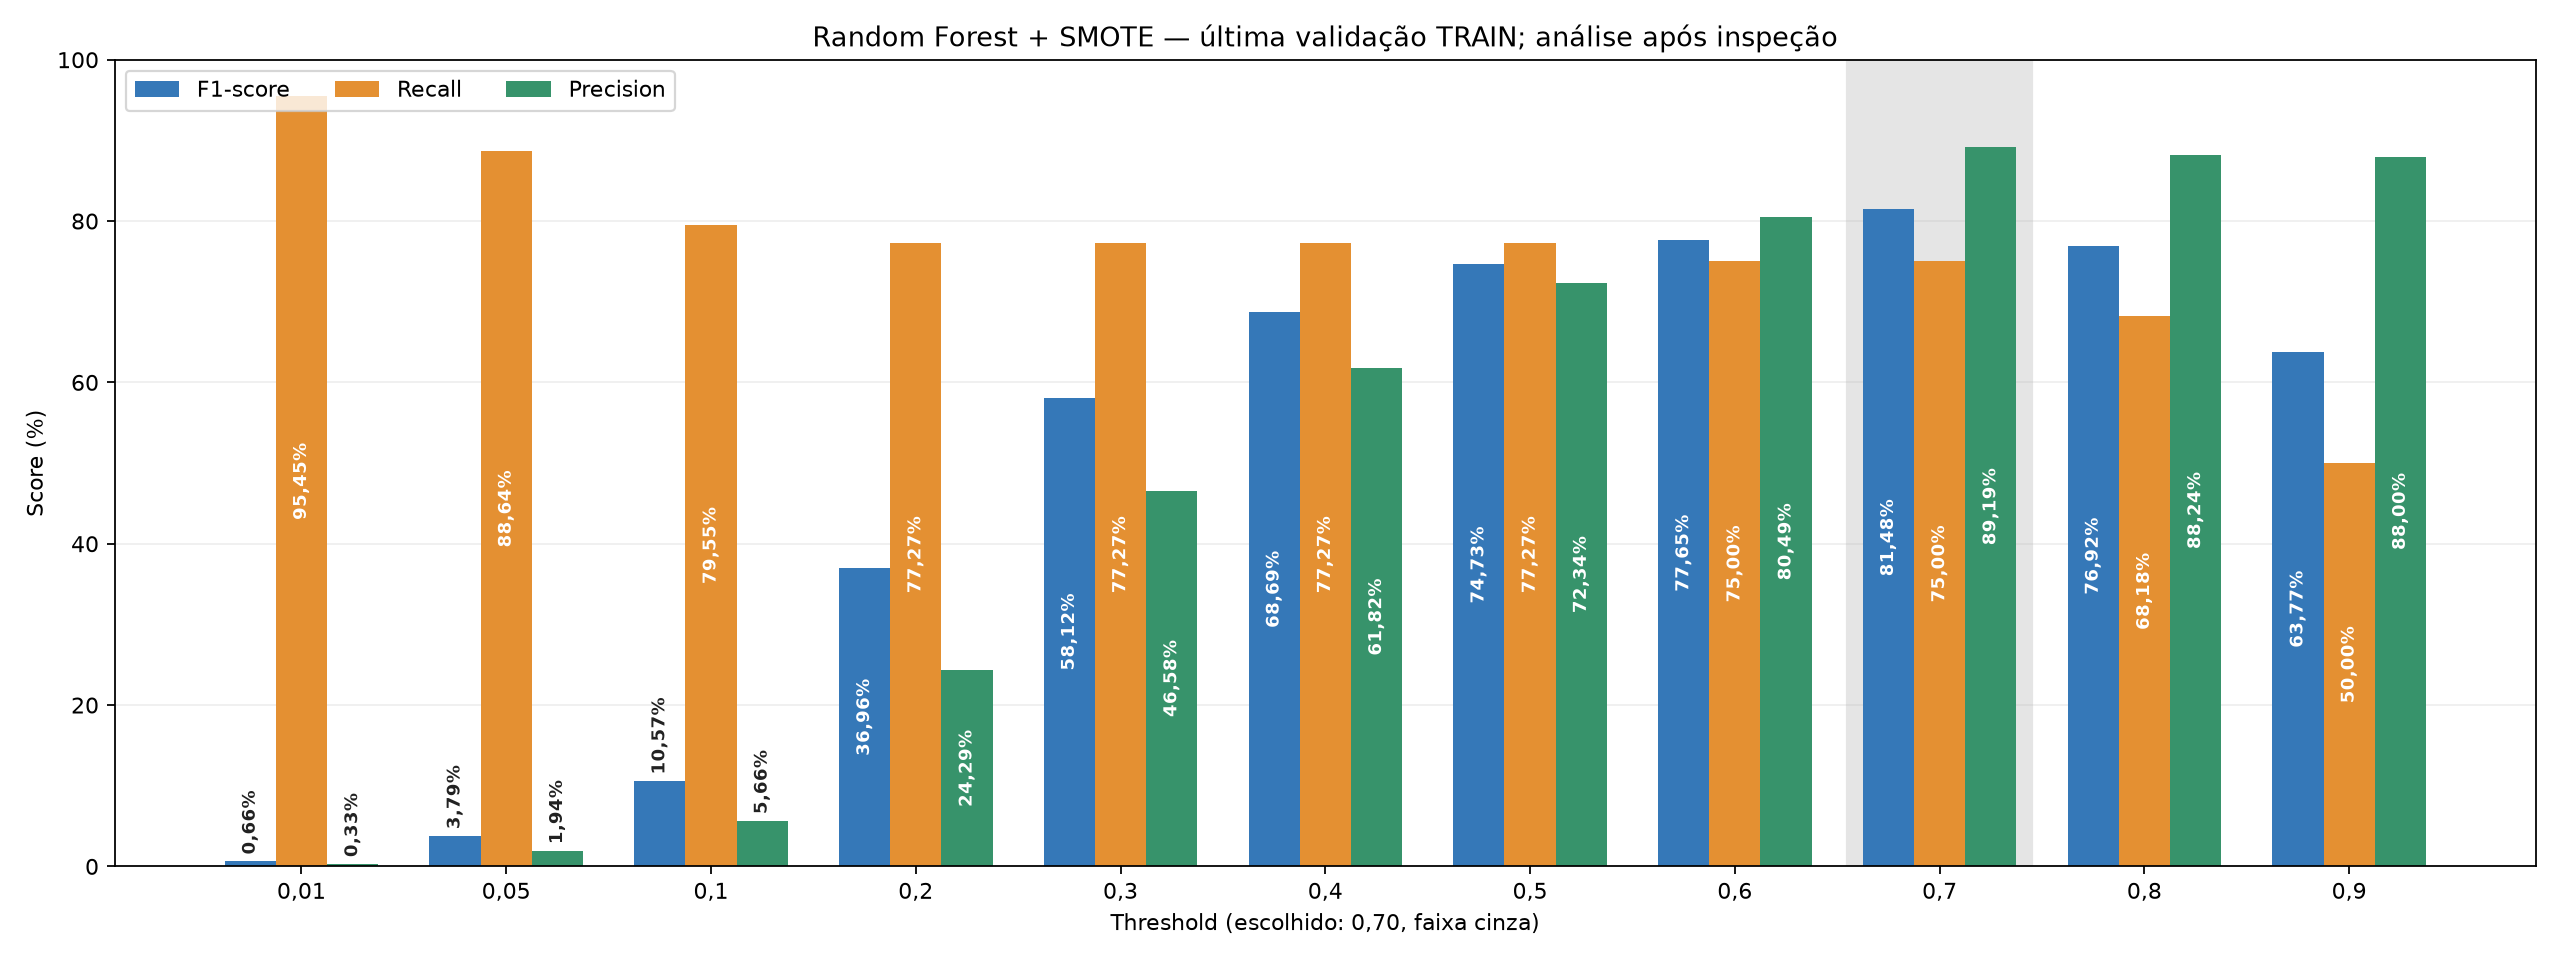

In [12]:
show(table("thresholds")[["threshold", "f1", "recall", "precision", "tp", "fp", "fn", "tn", "alerts"]])
figure("thresholds", 1300)

## 12. Fraudes e erros por faixa de feature

As fronteiras das faixas são aprendidas no treino do fold 3 e aplicadas à sua
validação, agora com threshold 0,70. Não são modalidades reais de fraude.

- **Fraude na faixa (%):** fraudes reais / transações na faixa.
- **Recall da faixa (%):** TP/(TP+FN).
- **Precision da faixa (%):** TP/(TP+FP).
- **FPR da faixa (%):** FP/(FP+TN), legítimas alertadas.
- **Alertas falsos (%):** FP/(FP+TP), parcela de alertas que era legítima.

Cada taxa precisa ser lida com sua contagem. “Não definido” indica denominador
zero. As mesmas transações aparecem em várias features, então não se deve somar
linhas de features diferentes. Estes são diagnósticos, sem nova seleção de atributos.

In [13]:
# Altere somente esta variável para inspecionar outra feature já calculada.
FEATURE_TO_INSPECT = "V10"
segments = table("category_errors")
show(segments.loc[segments.feature.eq(FEATURE_TO_INSPECT), [
    "feature", "bin", "count", "fraud_count", "legitimate_count", "tp", "fp", "fn", "tn",
    "fraud_rate_pct", "recall_pct", "precision_pct", "false_positive_rate_pct",
    "missed_fraud_rate_pct", "false_alert_share_pct", "alert_rate_pct",
]])
display(Markdown("O CSV **reports/metrics/model_select_category_errors.csv** contém as 30 features."))

,Feature,Faixa de valores,Quantidade,Fraudes confirmadas,Transações legítimas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Fraude na faixa (%),Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Fraudes não detectadas (%),Alertas que eram falsos (%),Taxa de alertas da faixa (%)
91,V10,"(-1.019, -0.631]",6.244,1,6.243,0,0,1,6.243,0.0160%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
92,V10,"(0.933, inf]",9.050,3,9.047,0,0,3,9.047,0.0331%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
93,V10,"(0.578, 0.933]",4.786,0,4.786,0,0,0,4.786,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
94,V10,"(-inf, -1.019]",5.445,35,5.410,31,4,4,5.406,0.6428%,88.57%,88.57%,0.07%,11.4286%,11.43%,0.64%
95,V10,"(-0.631, -0.413]",4.646,0,4.646,0,0,0,4.646,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
96,V10,"(-0.256, -0.115]",4.020,0,4.020,0,0,0,4.020,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
97,V10,"(0.0119, 0.209]",6.064,2,6.062,0,0,2,6.062,0.0330%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%
98,V10,"(-0.413, -0.256]",4.007,0,4.007,0,0,0,4.007,0.0000%,Não definido,Não definido,0.00%,Não definido,Não definido,0.00%
99,V10,"(0.209, 0.578]",6.460,2,6.458,2,0,0,6.458,0.0310%,100.00%,100.00%,0.00%,0.0000%,0.00%,0.03%
100,V10,"(-0.115, 0.0119]",3.437,1,3.436,0,0,1,3.436,0.0291%,0.00%,Não definido,0.00%,100.0000%,Não definido,0.00%


O CSV **reports/metrics/model_select_category_errors.csv** contém as 30 features.

## 13. Conclusão e limite da avaliação

O resultado principal é o **último fold temporal do TRAIN**. A análise separa
esse recorte da média/dispersão dos folds e do OOF agregado, todos em threshold 0,70.
Não há comparação com XGBoost, under, controles ou outros candidatos neste notebook.

O histórico de escolhas nos mesmos folds pode tornar as estimativas otimistas.
O dataset cobre dois dias e não permite auditar IDs de cliente/cartão ou o PCA
original. Não foram estimados intervalos temporais robustos nem custos financeiros.
Os folds reconstruídos reproduziram as métricas originais; isso verifica a
reprodução, sem transformar os dados em avaliação independente.

### TEST histórico — fora desta análise

**Nenhum TEST foi avaliado para montar este notebook.** Os 89,19% e 75% não devem
ser apresentados como resultados de TEST. A avaliação histórica já existente do
pipeline reajustado em todo o TRAIN está separada em
[04_final_test_metrics.ipynb](04_final_test_metrics.ipynb). Ela já havia sido
consultada; uma avaliação independente após estas escolhas exige dados novos.
Não houve refit final nem substituição desse artefato histórico.

In [14]:
display(Markdown(
    f"**Última validação TRAIN:** Precision **{result['precision']:.2%}**, "
    f"Recall **{result['recall']:.2%}**, F1 **{result['f1']:.2%}**, "
    f"AP **{result['average_precision']:.4f}**. "
    f"**{result['tp']}** fraudes detectadas, **{result['fn']}** não detectadas "
    f"e **{result['fp']}** falsos alertas; threshold **{result['threshold']}**."
))
display(manifest["limitations"])

**Última validação TRAIN:** Precision **89.19%**, Recall **75.00%**, F1 **81.48%**, AP **0.7130**. **33** fraudes detectadas, **11** não detectadas e **4** falsos alertas; threshold **0.7**.

['89,19% de Precision e 75% de Recall pertencem somente ao último fold TRAIN.',
 'Modelo e threshold escolhidos após observar os folds; resultado exploratório, sem validação externa à escolha.',
 'OOF agregado difere da média entre folds; o prefixo inicial só treina.',
 'Treino cresce e períodos mudam; gráfico por fold não é learning curve controlada.',
 'Importâncias e erros por faixas são diagnósticos, sem causalidade ou novo feature engineering.',
 'Dados cobrem dois dias; scores não foram calibrados; confirmação independente exige dados novos.']